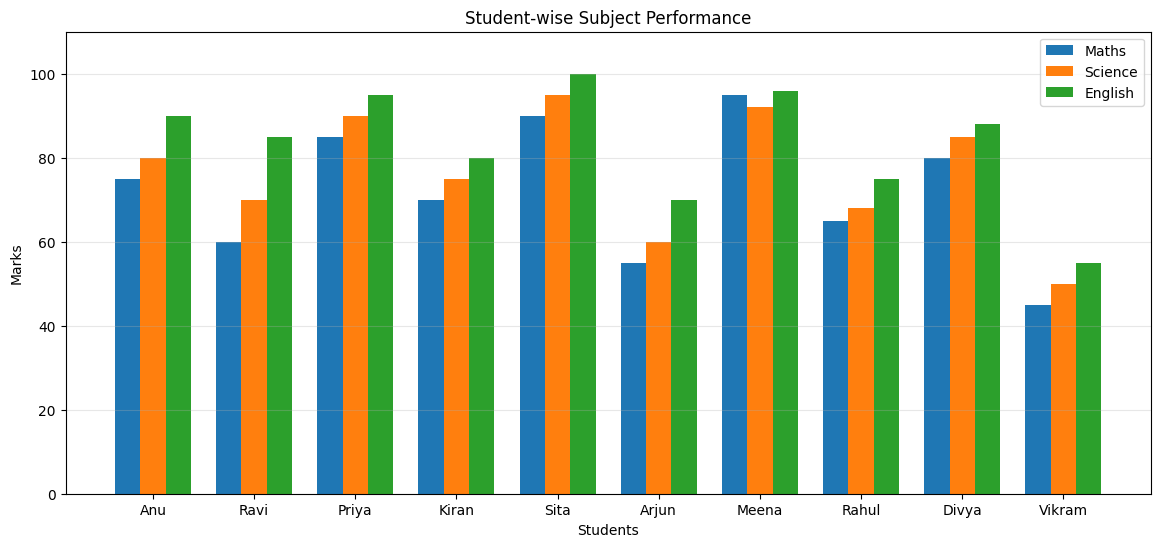

     Name  Average_Marks
4    Sita      95.000000
6   Meena      94.333333
2   Priya      90.000000
8   Divya      84.333333
0     Anu      81.666667
3   Kiran      75.000000
1    Ravi      71.666667
7   Rahul      69.333333
5   Arjun      61.666667
9  Vikram      50.000000


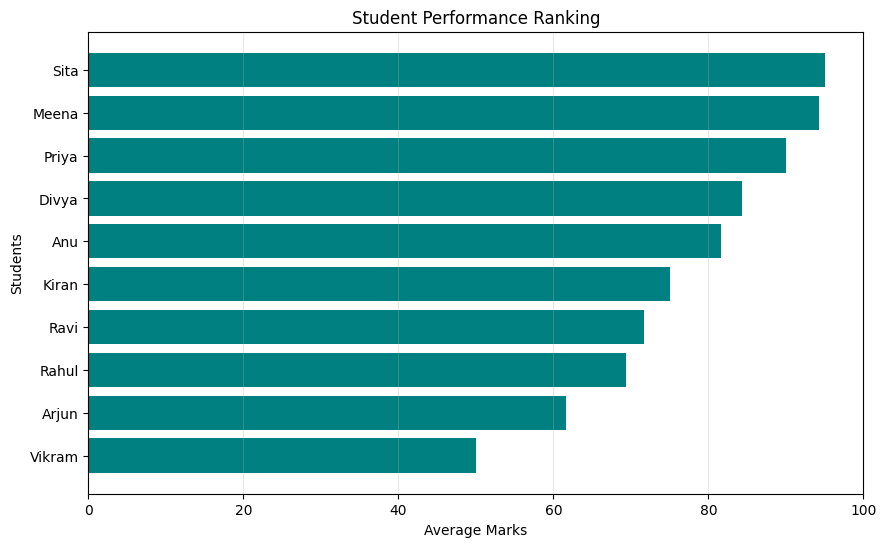

     Name  Average_Marks Pass_Status
0     Anu      81.666667        Pass
1    Ravi      71.666667        Pass
2   Priya      90.000000        Pass
3   Kiran      75.000000        Pass
4    Sita      95.000000        Pass
5   Arjun      61.666667        Pass
6   Meena      94.333333        Pass
7   Rahul      69.333333        Pass
8   Divya      84.333333        Pass
9  Vikram      50.000000        Pass
Pass_Status
Pass    10
Name: count, dtype: int64


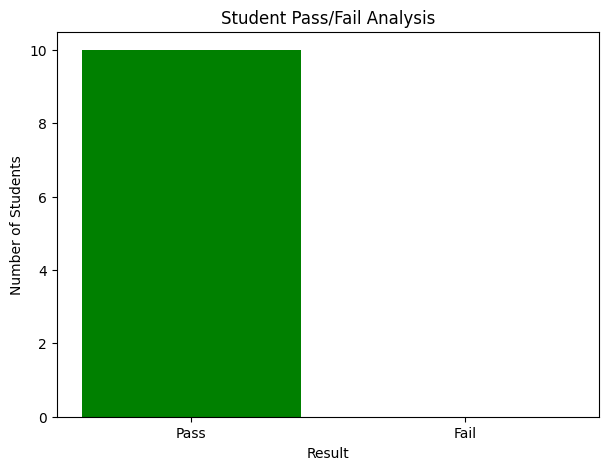

<Figure size 900x600 with 0 Axes>

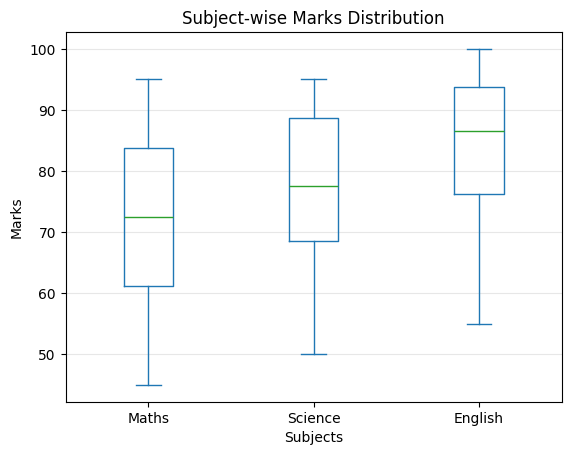

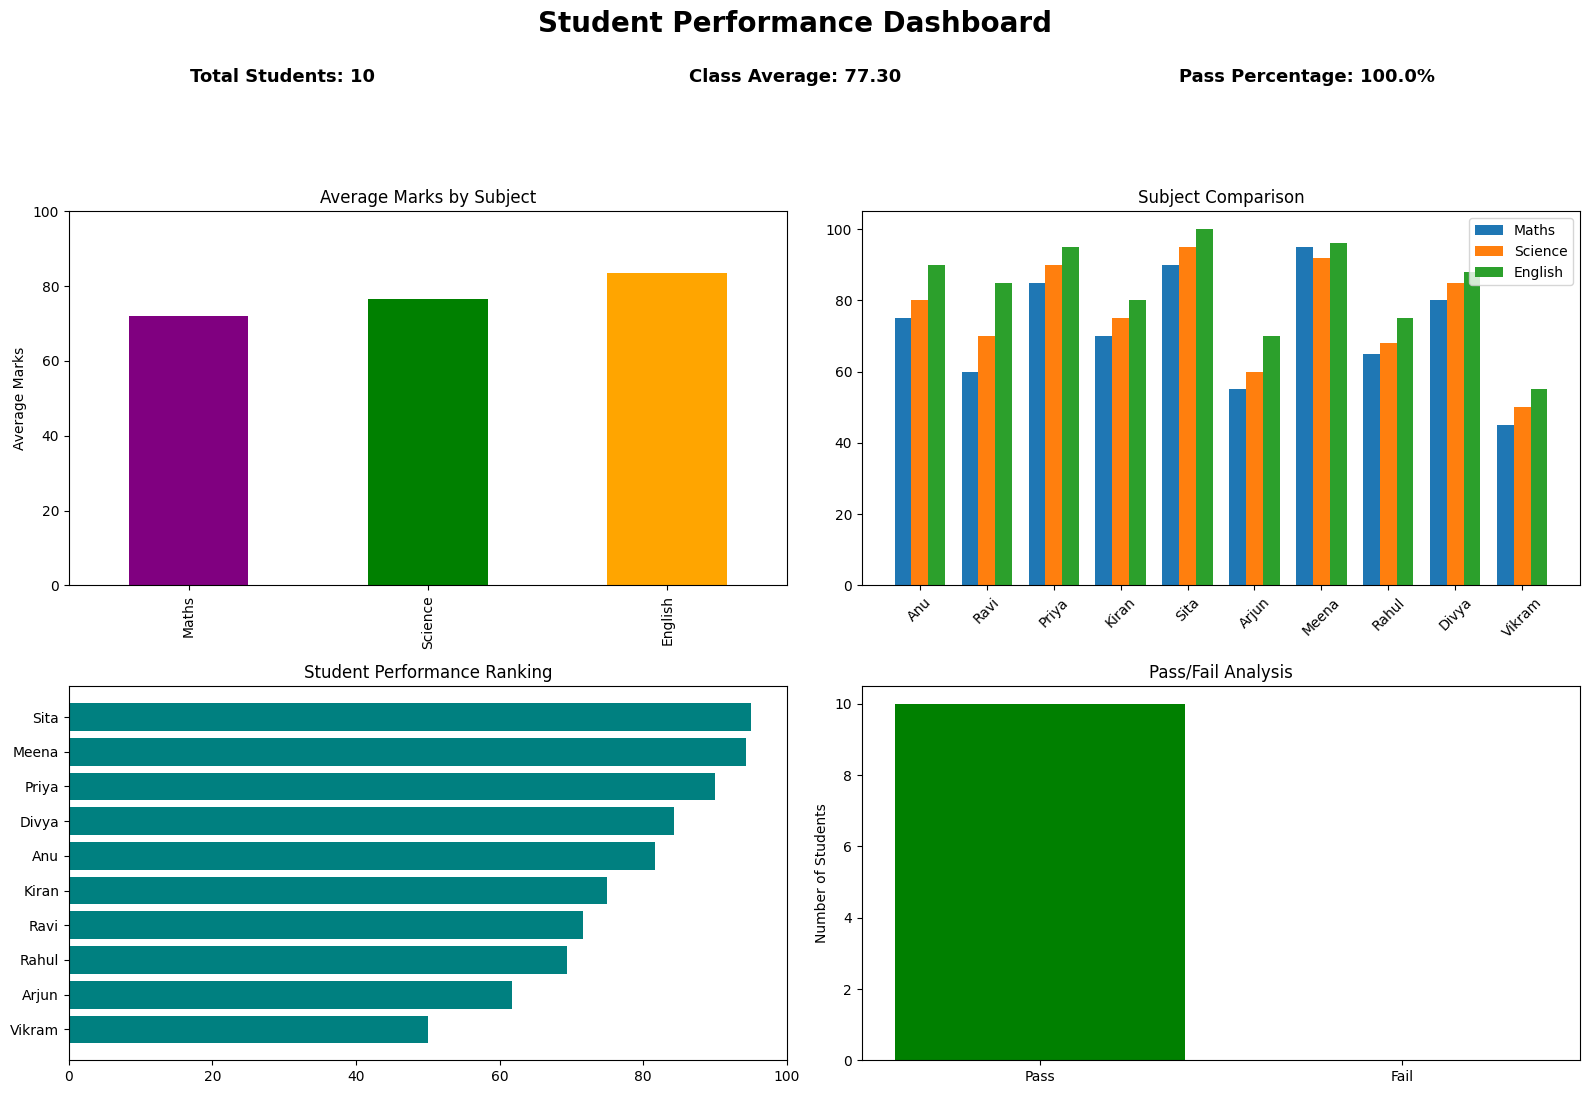

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = {
    "Student_ID": [101, 102, 103, 104, 105, 106, 107, 108, 109, 110],
    "Name": [
        "Anu", "Ravi", "Priya", "Kiran", "Sita",
        "Arjun", "Meena", "Rahul", "Divya", "Vikram"
    ],
    "Maths": [75, 60, 85, 70, 90, 55, 95, 65, 80, 45],
    "Science": [80, 70, 90, 75, 95, 60, 92, 68, 85, 50],
    "English": [90, 85, 95, 80, 100, 70, 96, 75, 88, 55]
}

df = pd.DataFrame(data)

subjects = ["Maths", "Science", "English"]

df["Total_Marks"] = df[subjects].sum(axis=1)

df["Average_Marks"] = df[subjects].mean(axis=1)

conditions = [
    df["Average_Marks"] >= 75,
    df["Average_Marks"] >= 60,
    df["Average_Marks"] >= 40
]

choices = ["Excellent", "Good", "Pass"]

df["Result"] = np.select(
    conditions,
    choices,
    default="Fail"
)
students = df["Name"]

x = np.arange(len(students))
width = 0.25

plt.figure(figsize=(14, 6))

plt.bar(x - width, df["Maths"], width, label="Maths")
plt.bar(x, df["Science"], width, label="Science")
plt.bar(x + width, df["English"], width, label="English")

plt.title("Student-wise Subject Performance")
plt.xlabel("Students")
plt.ylabel("Marks")

plt.xticks(x, students)
plt.ylim(0, 110)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

ranked_students = df.sort_values(
    by="Average_Marks",
    ascending=False
)

print(ranked_students[["Name", "Average_Marks"]])

plt.figure(figsize=(10, 6))

plt.barh(
    ranked_students["Name"],
    ranked_students["Average_Marks"],
    color="teal"
)

plt.title("Student Performance Ranking")
plt.xlabel("Average Marks")
plt.ylabel("Students")

plt.xlim(0, 100)
plt.gca().invert_yaxis()

plt.grid(axis="x", alpha=0.3)
plt.show()

df["Pass_Status"] = np.where(
    df["Average_Marks"] >= 40,
    "Pass",
    "Fail"
)

print(df[["Name", "Average_Marks", "Pass_Status"]])

pass_counts = df["Pass_Status"].value_counts()

print(pass_counts)

pass_counts = pass_counts.reindex(
    ["Pass", "Fail"],
    fill_value=0
)

plt.figure(figsize=(7, 5))

plt.bar(
    pass_counts.index,
    pass_counts.values,
    color=["green", "red"]
)

plt.title("Student Pass/Fail Analysis")
plt.xlabel("Result")
plt.ylabel("Number of Students")

plt.show()

plt.figure(figsize=(9, 6))

df[subjects].plot(kind="box")

plt.title("Subject-wise Marks Distribution")
plt.xlabel("Subjects")
plt.ylabel("Marks")
plt.grid(axis="y", alpha=0.3)

plt.show()

total_students = len(df)

class_average = df["Average_Marks"].mean()

pass_percentage = (
    (df["Pass_Status"] == "Pass").sum()
    / total_students
) * 100

fig, ax = plt.subplots(2, 2, figsize=(16, 11))

# Dashboard summary metrics
fig.text(
    0.18, 0.925,
    f"Total Students: {total_students}",
    ha="center", fontsize=13, fontweight="bold"
)

fig.text(
    0.50, 0.925,
    f"Class Average: {class_average:.2f}",
    ha="center", fontsize=13, fontweight="bold"
)

fig.text(
    0.82, 0.925,
    f"Pass Percentage: {pass_percentage:.1f}%",
    ha="center", fontsize=13, fontweight="bold"
)

# 1. Subject-wise average
subject_averages.plot(
    kind="bar",
    ax=ax[0, 0],
    color=["purple", "green", "orange"]
)
ax[0, 0].set_title("Average Marks by Subject")
ax[0, 0].set_ylabel("Average Marks")
ax[0, 0].set_ylim(0, 100)

# 2. Student-wise subject comparison
x = np.arange(len(df))
width = 0.25

ax[0, 1].bar(x - width, df["Maths"], width, label="Maths")
ax[0, 1].bar(x, df["Science"], width, label="Science")
ax[0, 1].bar(x + width, df["English"], width, label="English")

ax[0, 1].set_title("Subject Comparison")
ax[0, 1].set_xticks(x)
ax[0, 1].set_xticklabels(df["Name"], rotation=45)
ax[0, 1].legend()

# 3. Student ranking
ax[1, 0].barh(
    ranked_students["Name"],
    ranked_students["Average_Marks"],
    color="teal"
)
ax[1, 0].set_title("Student Performance Ranking")
ax[1, 0].set_xlim(0, 100)
ax[1, 0].invert_yaxis()

# 4. Pass/fail analysis
ax[1, 1].bar(
    pass_counts.index,
    pass_counts.values,
    color=["green", "red"]
)
ax[1, 1].set_title("Pass/Fail Analysis")
ax[1, 1].set_ylabel("Number of Students")

fig.suptitle(
    "Student Performance Dashboard",
    fontsize=20,
    fontweight="bold",
    y=0.99
)

plt.tight_layout(rect=[0, 0, 1, 0.88])

fig.savefig(
    "student_performance_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

df.to_csv("student_performance_results.csv", index=False)

plt.show()
